# Regression Discontinuity — Health Insurance Coverage at Age 65

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 1-year PUMS (pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a
retrieval fails, a key is absent or a value is malformed, the notebook stops.

It reads ACS PUMS through a client that returns **weighted cell counts only**. No person-level row
is read, printed or stored anywhere below. The analysis was fixed in a **pre-analysis plan**
(`pap/C02_pap.md`) committed before any table here was retrieved, and the notebook is bound to
that file by its SHA-256.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** why a threshold rule such as an eligibility age behaves like an experiment, and what
   has to be true for that to hold.
2. **Estimate** a jump at a threshold with a local-linear fit and a triangular kernel, and show the
   estimate against the binned means it summarises.
3. **Report** how the answer moves with the bandwidth instead of presenting one bandwidth as the answer.
4. **Run** three falsification tests — a balance check on the running variable, placebo cutoffs and
   covariate continuity — and apply a decision rule written before the data were seen.
5. **State** what a discrete running variable and survey weights do to the estimand.

## Prerequisites

**Knowledge.** Weighted least squares; the idea of a local comparison; why a regression line on each
side of a cutoff can estimate a jump.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you
as the environment variable `CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path
you set in `KRL_SECRETS_PATH`. The key is read at runtime and is never printed or written into this
notebook's output. The retrieval makes about 150 requests and takes several minutes.

**Packages.** `pandas`, `numpy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package
(its `methods.rdd` module holds the estimators).

**Prior notebooks.** None are required. C01 introduces the identification contract used here.

## Data Provenance

| Variable | Meaning | Role |
|---|---|---|
| `AGEP` | age in completed years | running variable (ages 55–75) |
| `HICOV` | health insurance coverage recode | primary outcome (1 = with coverage) |
| `PUBCOV`, `PRIVCOV` | public and private coverage recodes | decomposition of the outcome |
| `SEX`, `SCHL` | sex; educational attainment | covariates for the continuity check |
| `PWGTP` | person weight | cell weight |

Published labels for every variable are fetched from the Census variables endpoint and recorded in
each provenance file, with the SHA-256 of the pre-analysis plan. One request per state (50 states and
the District of Columbia) for each of three aggregations; each file is a replayable request.

> **Cells, not people.** `fetch_acs_pums` sums the person weights within each combination of the
> grouping columns and returns those sums. Cells with fewer than 10 records are withheld, and the
> notebook reports how many records that is.

## Design and identification

**Estimand.** The jump, at the age-65 threshold, in the survey-weighted share of people with health
insurance, in percentage points — local to age 65.

**Assumption.** Everything other than Medicare eligibility changes smoothly through age 65. Age cannot
be chosen, so the usual worry — people steering themselves across the cutoff — does not apply in its
usual form; what can still break the assumption is another rule that also changes at 65.

**Decision rule, fixed in the plan.** The jump counts as null if its 95% interval at the headline
bandwidth contains zero. It counts as credible only if all three falsifications pass.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import rdd
from krl_tutorials_data.sources import DataAccessError, fetch_acs, fetch_acs_pums

NB_DIR = REPO_ROOT / "projects" / "09-causal-identification" / "C02_medicare_age65_rdd"
PAP = NB_DIR / "pap" / "C02_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()

YEAR = 2023
CUTOFF = 64.5                      # between 64 and 65 on the AGEP scale; treated side is AGEP >= 65
HEADLINE_K = 5                     # whole years on each side; bandwidth = k - 0.5
GRID_K = list(range(3, 11))
AGE_LO, AGE_HI = 55, 75

print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"vintage           : ACS {YEAR} 1-year PUMS; cutoff {CUTOFF}; headline window = ages {65 - HEADLINE_K}-{64 + HEADLINE_K}")

pre-analysis plan : projects/09-causal-identification/C02_medicare_age65_rdd/pap/C02_pap.md
plan SHA-256      : 10f4182b7b8027d8dfecccd594998618c2964cd782622dd63db883ddb4d89754
vintage           : ACS 2023 1-year PUMS; cutoff 64.5; headline window = ages 60-69


### Retrieving the cells

Three aggregations, chosen so that few cells fall under the small-cell floor: coverage by single year
of age; sex by age; education by age. A state's request returns its cells; they are stacked here.

In [2]:
LABEL_URL = f"https://api.census.gov/data/{YEAR}/acs/acs1/pums/variables.json"
_labels = requests.get(LABEL_URL, timeout=60).json()["variables"]


def labels(*codes: str) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable."""
    return {code: _labels[code]["label"] for code in codes}


AGGREGATIONS = {
    "coverage": ["AGEP", "HICOV", "PRIVCOV", "PUBCOV"],
    "sex": ["AGEP", "SEX"],
    "education": ["AGEP", "SCHL"],
}

try:
    geo, _ = fetch_acs(year=YEAR, variables={"B01001_001E": "Estimate!!Total:"},
                       dataset="acs/acs1", geography="state:*")
except DataAccessError as exc:
    print(f"HALTED - could not list the states: {type(exc).__name__}: {exc}")
    raise
fips = sorted(code for code in geo["state"] if code != "72")      # Puerto Rico is outside the plan
print(f"states requested : {len(fips)} (50 states and the District of Columbia)")

stacked: dict[str, list[pd.DataFrame]] = {name: [] for name in AGGREGATIONS}
withheld = {name: 0 for name in AGGREGATIONS}
withheld_weight = {name: 0.0 for name in AGGREGATIONS}
kept = {name: 0 for name in AGGREGATIONS}
out_dir = NB_DIR / "provenance"
try:
    for name, by in AGGREGATIONS.items():
        for code in fips:
            frame, prov = fetch_acs_pums(
                year=YEAR, variables=labels(*by), aggregate_by=by, geography=f"state:{code}",
                keep={"AGEP": (AGE_LO, AGE_HI)},
            )
            stacked[name].append(frame)
            withheld[name] += int(frame.attrs["suppressed_records"])
            withheld_weight[name] += float(frame.attrs["suppressed_weighted_n"])
            kept[name] += int(frame["n_records"].sum())
            prov.with_pap(PAP).write(out_dir / f"c02_pums{YEAR}_{name}_{code}.json")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

cells_ = {name: pd.concat(parts, ignore_index=True) for name, parts in stacked.items()}
for name, frame in cells_.items():
    total = kept[name] + withheld[name]
    print(f"{name:10s}: {len(frame):6,} cells; records in the cells {kept[name]:>9,}; withheld by the 10-record floor {withheld[name]:>6,} "
          f"({withheld[name] / total:.2%} of the {total:,} records at ages {AGE_LO}-{AGE_HI})")

states requested : 51 (50 states and the District of Columbia)


coverage  :  3,422 cells; records in the cells   961,930; withheld by the 10-record floor  3,108 (0.32% of the 965,038 records at ages 55-75)
sex       :  2,142 cells; records in the cells   965,038; withheld by the 10-record floor      0 (0.00% of the 965,038 records at ages 55-75)
education : 10,754 cells; records in the cells   936,748; withheld by the 10-record floor 28,290 (2.93% of the 965,038 records at ages 55-75)


In [3]:
"""One row per single year of age: weighted outcome shares and the weights."""
cov = cells_["coverage"]
weight = cov.groupby("AGEP")["weighted_n"].sum()


def share(frame: pd.DataFrame, mask: pd.Series, base: pd.Series) -> pd.Series:
    """Weighted percentage of each age's population satisfying ``mask``."""
    return 100.0 * frame[mask].groupby("AGEP")["weighted_n"].sum().reindex(base.index).fillna(0.0) / base


ages = pd.DataFrame({"weight": weight})
ages["any_coverage"] = share(cov, cov["HICOV"] == 1, weight)
ages["public"] = share(cov, cov["PUBCOV"] == 1, weight)
ages["private"] = share(cov, cov["PRIVCOV"] == 1, weight)
ages["records"] = cov.groupby("AGEP")["n_records"].sum()

sex = cells_["sex"]
sex_w = sex.groupby("AGEP")["weighted_n"].sum()
ages["female"] = share(sex, sex["SEX"] == 2, sex_w)
edu = cells_["education"]
edu_w = edu.groupby("AGEP")["weighted_n"].sum()
ages["bachelors_plus"] = share(edu, edu["SCHL"] >= 21, edu_w)

ages.index.name = "age"
show = ages.assign(weight_millions=ages["weight"] / 1e6)[["weight_millions", "records", "any_coverage", "public", "private"]]
print(show.round(2).to_string())

     weight_millions  records  any_coverage  public  private
age                                                         
55              3.90    42322         91.62   19.19    76.57
56              3.85    42068         91.79   19.87    76.28
57              3.96    43581         92.16   20.44    76.40
58              4.18    46560         92.55   20.62    76.50
59              4.22    47842         92.55   21.52    75.83
60              4.42    50066         92.49   22.59    74.99
61              4.29    49532         92.85   22.72    75.35
62              4.38    50956         93.34   24.95    74.41
63              4.31    50649         93.02   25.52    73.63
64              4.22    50453         93.64   28.35    72.95
65              4.02    50975         98.16   81.01    52.95
66              3.92    50154         98.73   87.08    50.99
67              3.80    48718         99.00   92.16    49.57
68              3.69    47689         99.10   93.66    49.58
69              3.54    

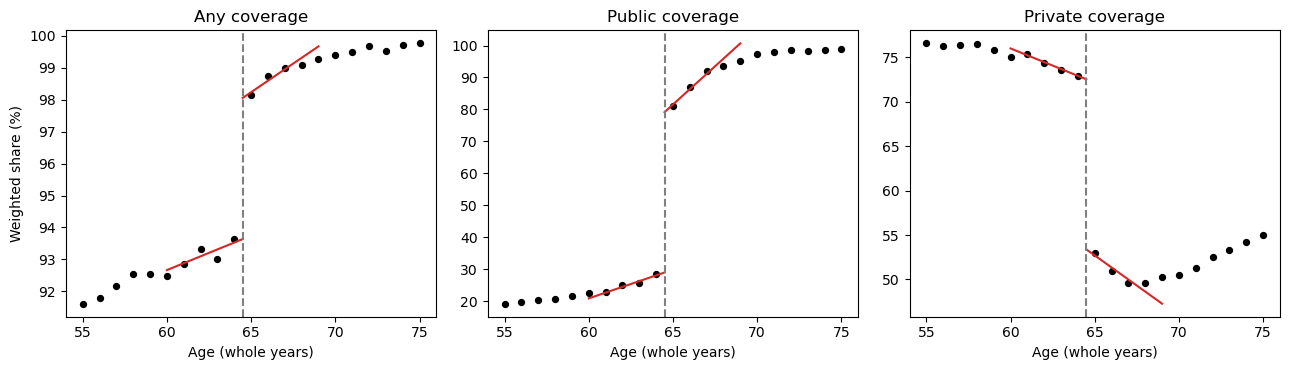

In [4]:
"""The discontinuity plot: binned means (one bin per year of age) and a local-linear line each side."""
x = ages.index.to_numpy(dtype=float)
w = ages["weight"].to_numpy()
BW = HEADLINE_K - 0.5


def side_line(y: np.ndarray, left: bool) -> tuple[np.ndarray, np.ndarray]:
    """Weighted straight-line fit on one side of the cutoff, triangular kernel."""
    keep = (x < CUTOFF) if left else (x > CUTOFF)
    keep &= np.abs(x - CUTOFF) <= BW
    kernel = 1.0 - np.abs(x[keep] - CUTOFF) / BW
    slope, intercept = np.polyfit(x[keep] - CUTOFF, y[keep], 1, w=np.sqrt(kernel * w[keep]))
    grid = np.linspace(x[keep].min(), CUTOFF, 20) if left else np.linspace(CUTOFF, x[keep].max(), 20)
    return grid, intercept + slope * (grid - CUTOFF)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, col, title in zip(axes, ["any_coverage", "public", "private"],
                          ["Any coverage", "Public coverage", "Private coverage"]):
    yv = ages[col].to_numpy()
    ax.scatter(x, yv, s=18, color="black")
    for left in (True, False):
        gx, gy = side_line(yv, left)
        ax.plot(gx, gy, color="tab:red")
    ax.axvline(CUTOFF, color="grey", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Age (whole years)")
axes[0].set_ylabel("Weighted share (%)")
plt.tight_layout()
plt.show()

### The estimate, and what the bandwidth does to it

A bandwidth of *k* years takes ages 65−*k* to 64 and 65 to 64+*k*. The headline is *k* = 5, fixed in the
plan; the grid shows every outcome at every width from 3 to 10.

In [5]:
"""Headline estimates and the bandwidth grid for the three outcomes."""
OUTCOMES = {"any_coverage": "any coverage", "public": "public coverage", "private": "private coverage"}
rows = []
fits = {}
for col, name in OUTCOMES.items():
    for k in GRID_K:
        fit = rdd.local_linear(x, ages[col].to_numpy(), cutoff=CUTOFF, bandwidth=k - 0.5,
                               kernel="triangular", weights=w)
        fits[(col, k)] = fit
        rows.append({"outcome": name, "k": k, "jump_pp": fit.estimate, "se": fit.se,
                     "lo": fit.estimate - 1.96 * fit.se, "hi": fit.estimate + 1.96 * fit.se,
                     "n_left": fit.n_left, "n_right": fit.n_right})
grid = pd.DataFrame(rows)
head_fit = fits[("any_coverage", HEADLINE_K)]
print(f"Headline (k = {HEADLINE_K}): ages {65 - HEADLINE_K}-{64 + HEADLINE_K} are in the window, but the triangular kernel gives the end ages weight zero, "
      f"so {head_fit.n_left} ages on the left and {head_fit.n_right} on the right carry the fit (ages {66 - HEADLINE_K}-{63 + HEADLINE_K}).")
print(grid[grid["k"] == HEADLINE_K].round(3).to_string(index=False))
exact = grid[grid["k"] == min(GRID_K)]
print(f"k = {min(GRID_K)} is not printed: after the kernel drops the end ages {int(exact['n_left'].iloc[0])} ages remain per side, the line fits them exactly "
      f"and the standard error is {float(exact['se'].max()):.1f}, which is not an estimate of uncertainty.")
print()
print("Bandwidth sensitivity of the jump (pp), k from 4:")
print(grid[grid["k"] > min(GRID_K)].pivot(index="k", columns="outcome", values="jump_pp").round(2).to_string())

# the straight-line fits drawn above must reproduce the library's headline estimate
for col in OUTCOMES:
    yv = ages[col].to_numpy()
    (lx, ly), (rx, ry) = side_line(yv, True), side_line(yv, False)
    drawn = float(ry[0] - ly[-1])
    assert abs(drawn - fits[(col, HEADLINE_K)].estimate) < 1e-8, col
print()
print("The lines in the figure reproduce the library estimate for all three outcomes.")

Headline (k = 5): ages 60-69 are in the window, but the triangular kernel gives the end ages weight zero, so 4 ages on the left and 4 on the right carry the fit (ages 61-68).
         outcome  k  jump_pp    se      lo      hi  n_left  n_right
    any coverage  5    4.417 0.243   3.940   4.893       4        4
 public coverage  5   50.198 1.157  47.929  52.466       4        4
private coverage  5  -19.141 0.463 -20.048 -18.234       4        4
k = 3 is not printed: after the kernel drops the end ages 2 ages remain per side, the line fits them exactly and the standard error is 0.0, which is not an estimate of uncertainty.

Bandwidth sensitivity of the jump (pp), k from 4:
outcome  any coverage  private coverage  public coverage
k                                                       
4                4.30            -18.81            49.20
5                4.42            -19.14            50.20
6                4.46            -19.75            51.33
7                4.53            -20

In [6]:
"""Falsification 1: the two sides of the cutoff are equally populated."""
counts = ages["records"].astype(int)
in_window = counts[(counts.index >= 65 - HEADLINE_K) & (counts.index <= 64 + HEADLINE_K)]
x_records = np.repeat(in_window.index.to_numpy(dtype=float), in_window.to_numpy())   # ages only, repeated
dens = rdd.density_test(x_records, cutoff=CUTOFF, bandwidth=HEADLINE_K - 0.5)
right_share = dens.n_right / (dens.n_left + dens.n_right)
DENSITY_PASS = abs(right_share - 0.5) <= 0.03
print(f"FALSIFICATION: balance of record counts either side of 65 | statistic={right_share:.4f} | left={dens.n_left:,} right={dens.n_right:,} binomial p={dens.p_value:.3g}, pass if within 0.03 of 0.5 | verdict={'PASS' if DENSITY_PASS else 'FAIL'}")

FALSIFICATION: balance of record counts either side of 65 | statistic=0.4921 | left=251,656 right=243,789 binomial p=5.38e-29, pass if within 0.03 of 0.5 | verdict=PASS


In [7]:
"""Falsification 2: placebo cutoffs where no rule changes."""
placebos = rdd.placebo_cutoffs(
    x, ages["any_coverage"].to_numpy(), true_cutoff=CUTOFF, placebo_cutoffs=[59.5, 69.5],
    bandwidth=HEADLINE_K - 0.5, kernel="triangular", weights=w,
)
PLACEBO_PASS = True
for p in placebos:
    lo, hi = p.fit.estimate - 1.96 * p.fit.se, p.fit.estimate + 1.96 * p.fit.se
    ok = lo <= 0.0 <= hi
    PLACEBO_PASS &= ok
    print(f"FALSIFICATION: placebo cutoff at {p.cutoff + 0.5:.0f} | statistic={p.fit.estimate:.3f} | jump in pp, 95% interval [{lo:+.3f}, {hi:+.3f}] | verdict={'PASS' if ok else 'FAIL'}")

FALSIFICATION: placebo cutoff at 60 | statistic=-0.334 | jump in pp, 95% interval [-0.697, +0.030] | verdict=PASS
FALSIFICATION: placebo cutoff at 70 | statistic=0.008 | jump in pp, 95% interval [-0.083, +0.098] | verdict=PASS


In [8]:
"""Falsification 3: covariates do not jump at 65."""
COVARIATE_PASS = True
print("(the cell weights here are the coverage cells' populations, not weights built for sex or education)")
for col, name in (("female", "share female"), ("bachelors_plus", "share with a bachelor's degree or higher")):
    fit = rdd.local_linear(x, ages[col].to_numpy(), cutoff=CUTOFF, bandwidth=HEADLINE_K - 0.5,
                           kernel="triangular", weights=w)
    lo, hi = fit.estimate - 1.96 * fit.se, fit.estimate + 1.96 * fit.se
    ok = lo <= 0.0 <= hi
    COVARIATE_PASS &= ok
    print(f"FALSIFICATION: covariate continuity, {name} | statistic={fit.estimate:.3f} | jump in pp, 95% interval [{lo:+.3f}, {hi:+.3f}] | verdict={'PASS' if ok else 'FAIL'}")

(the cell weights here are the coverage cells' populations, not weights built for sex or education)
FALSIFICATION: covariate continuity, share female | statistic=-0.244 | jump in pp, 95% interval [-1.057, +0.568] | verdict=PASS
FALSIFICATION: covariate continuity, share with a bachelor's degree or higher | statistic=-0.355 | jump in pp, 95% interval [-0.778, +0.068] | verdict=PASS


In [9]:
"""The decision rule from the plan, applied as written."""
head = fits[("any_coverage", HEADLINE_K)]
lo, hi = head.estimate - 1.96 * head.se, head.estimate + 1.96 * head.se
pub, prv = fits[("public", HEADLINE_K)], fits[("private", HEADLINE_K)]
print(f"Jump in any coverage at 65 (k = {HEADLINE_K}): {head.estimate:+.2f} pp, conventional 95% interval [{lo:+.2f}, {hi:+.2f}] (HC1 over {head.n_left + head.n_right} age cells with four parameters; see the added bias-aware interval below).")
print(f"Public coverage {pub.estimate:+.2f} pp; private coverage {prv.estimate:+.2f} pp.")
print(f"Interval for any coverage contains zero (null by the plan's rule): {lo <= 0.0 <= hi}.")
print(f"Balance check passed: {DENSITY_PASS}; placebo cutoffs passed: {PLACEBO_PASS}; covariates passed: {COVARIATE_PASS}.")
if DENSITY_PASS and PLACEBO_PASS and COVARIATE_PASS:
    print("All three falsifications pass: by the plan's rule the design is credible at this threshold. These checks cannot see a change in survey processing at 65 (the added cell below reports the mean person weight on each side).")
else:
    print("At least one falsification fails: by the plan's rule the jump is reported as descriptive, not as an identified effect.")

Jump in any coverage at 65 (k = 5): +4.42 pp, conventional 95% interval [+3.94, +4.89] (HC1 over 8 age cells with four parameters; see the added bias-aware interval below).
Public coverage +50.20 pp; private coverage -19.14 pp.
Interval for any coverage contains zero (null by the plan's rule): False.
Balance check passed: True; placebo cutoffs passed: True; covariates passed: True.
All three falsifications pass: by the plan's rule the design is credible at this threshold. These checks cannot see a change in survey processing at 65 (the added cell below reports the mean person weight on each side).


### Added after review: not pre-specified (added after review, 2026-10-23)

The cells below were added after the stored results were reviewed. None replaces the plan's primary result, which is the conventional
interval above. They address records the small-cell floor withheld, the curvature a few age cells cannot rule out, a change in survey
processing at 65, and heaping of reported age at 60.

In [10]:
"""not pre-specified (added after review, 2026-10-23): withheld records, a pooled re-pull, unweighted jump, survey weights at 65."""
cov_withheld = withheld["coverage"]
W = withheld_weight["coverage"]
win = ages.loc[65 - HEADLINE_K: 64 + HEADLINE_K]
pop_left, pop_right = float(win.loc[win.index < 65, "weight"].sum()), float(win.loc[win.index >= 65, "weight"].sum())
print(f"withheld in the coverage aggregation: {cov_withheld:,} records, weighted {W / 1e6:.2f} million people, against {pop_left / 1e6 + pop_right / 1e6:.1f} million in the headline window")
lower_bound = head.estimate - 100 * W / (pop_right + W)
upper_bound = head.estimate + 100 * W / (pop_left + W)
print(f"bound: if every withheld person were uninsured and fell on one side, the jump would lie between {lower_bound:+.2f} and {upper_bound:+.2f} pp "
      f"(estimate {head.estimate:+.2f}); the bounds ignore which ages the withheld cells hold, so they are wide")

try:
    pooled, pooled_prov = fetch_acs_pums(
        year=YEAR, variables=labels(*AGGREGATIONS["coverage"]), aggregate_by=AGGREGATIONS["coverage"],
        geography=[f"state:{code}" for code in fips], keep={"AGEP": (AGE_LO, AGE_HI)},
    )
except DataAccessError as exc:
    print(f"HALTED - the pooled re-pull failed: {type(exc).__name__}: {exc}")
    raise
pooled_prov.with_pap(PAP).write(NB_DIR / "provenance" / f"c02_pums{YEAR}_coverage_pooled.json")
pw = pooled.groupby("AGEP")["weighted_n"].sum()
pooled_cov = 100.0 * pooled[pooled["HICOV"] == 1].groupby("AGEP")["weighted_n"].sum().reindex(pw.index).fillna(0.0) / pw
pooled_fit = rdd.local_linear(pw.index.to_numpy(dtype=float), pooled_cov.to_numpy(), cutoff=CUTOFF,
                              bandwidth=HEADLINE_K - 0.5, kernel="triangular", weights=pw.to_numpy())
print(f"states pooled before the floor: withheld {pooled.attrs['suppressed_records']:,} records; jump {pooled_fit.estimate:+.3f} pp (SE {pooled_fit.se:.3f}) "
      f"against {head.estimate:+.3f} in the stored run (difference {pooled_fit.estimate - head.estimate:+.3f})")

records_cov = 100.0 * cov[cov["HICOV"] == 1].groupby("AGEP")["n_records"].sum().reindex(ages.index).fillna(0.0) / ages["records"]
unw = rdd.local_linear(x, records_cov.to_numpy(), cutoff=CUTOFF, bandwidth=HEADLINE_K - 0.5, kernel="triangular",
                       weights=ages["records"].to_numpy(dtype=float))
print(f"unweighted jump (record counts, no person weights): {unw.estimate:+.3f} pp (SE {unw.se:.3f}) against {head.estimate:+.3f} weighted")
mean_w = cov.groupby("AGEP").apply(lambda d: d["weighted_n"].sum() / d["n_records"].sum(), include_groups=False)
print(f"mean person weight at age 64: {mean_w.loc[64]:.1f}; at age 65: {mean_w.loc[65]:.1f} (a change in survey processing at 65 would show here)")

withheld in the coverage aggregation: 3,108 records, weighted 0.29 million people, against 40.6 million in the headline window
bound: if every withheld person were uninsured and fell on one side, the jump would lie between +2.93 and +5.72 pp (estimate +4.42); the bounds ignore which ages the withheld cells hold, so they are wide


states pooled before the floor: withheld 0 records; jump +4.313 pp (SE 0.238) against +4.417 in the stored run (difference -0.104)
unweighted jump (record counts, no person weights): +4.325 pp (SE 0.211) against +4.417 weighted
mean person weight at age 64: 83.6; at age 65: 78.9 (a change in survey processing at 65 would show here)


In [11]:
"""not pre-specified (added after review, 2026-10-23): a bias-aware interval for a discrete running variable."""
y_any = ages["any_coverage"].to_numpy()
second_diff = np.abs(np.diff(y_any[x < CUTOFF], 2)).max(), np.abs(np.diff(y_any[x > CUTOFF], 2)).max()
print(f"largest second difference of the any-coverage series, per side (pp per year squared): {second_diff[0]:.3f} left, {second_diff[1]:.3f} right")
for m in (0.05, 0.1, 0.25, 0.5, 1.0):
    h = rdd.honest_interval(x, y_any, cutoff=CUTOFF, bandwidth=HEADLINE_K - 0.5, smoothness=m, weights=w)
    print(f"curvature bound M = {m:<5}: bias bound {h.bias_bound:.3f} pp, critical value {h.critical_value:.3f}, "
          f"95% interval [{h.lower:+.2f}, {h.upper:+.2f}] (conventional [{lo:+.2f}, {hi:+.2f}])")

largest second difference of the any-coverage series, per side (pp per year squared): 0.938 left, 0.361 right
curvature bound M = 0.05 : bias bound 0.199 pp, critical value 2.468, 95% interval [+3.82, +5.02] (conventional [+3.94, +4.89])
curvature bound M = 0.1  : bias bound 0.398 pp, critical value 3.281, 95% interval [+3.62, +5.21] (conventional [+3.94, +4.89])
curvature bound M = 0.25 : bias bound 0.994 pp, critical value 5.735, 95% interval [+3.02, +5.81] (conventional [+3.94, +4.89])
curvature bound M = 0.5  : bias bound 1.989 pp, critical value 9.825, 95% interval [+2.03, +6.81] (conventional [+3.94, +4.89])
curvature bound M = 1.0  : bias bound 3.977 pp, critical value 18.004, 95% interval [+0.04, +8.79] (conventional [+3.94, +4.89])


In [12]:
"""not pre-specified (added after review, 2026-10-23): a donut check on the placebo at 60, where reported ages heap."""
keep_age = x != 60
donut = rdd.placebo_cutoffs(x[keep_age], y_any[keep_age], true_cutoff=CUTOFF, placebo_cutoffs=[59.5],
                            bandwidth=HEADLINE_K - 0.5, kernel="triangular", weights=w[keep_age])[0]
print(f"placebo at 60 without age 60: {donut.fit.estimate:+.3f} pp, interval [{donut.fit.estimate - 1.96 * donut.fit.se:+.3f}, {donut.fit.estimate + 1.96 * donut.fit.se:+.3f}]")

placebo at 60 without age 60: -0.047 pp, interval [-0.776, +0.683]


## Limitations

- **Local to 65.** The estimate is the jump at one threshold. It says nothing about the effect of coverage
  at any other age, or about the people far from 65.
- **A discrete running variable.** Age is reported in whole years, so the nearest observations are a
  year apart and the fit rests on a handful of age cells per side. The conventional interval uses the heteroskedasticity-robust
  variance over those few cells, which understates the uncertainty, and it ignores the curvature a few points cannot rule out. The plan
  chose that interval and disclosed this; the added bias-aware interval shows how much wider it becomes for stated curvature bounds, and
  `rdrobust` is not adopted.
- **Survey weights change the estimand.** The jump is in the weighted mean, a different object from the unweighted jump, which is also reported.
- **Survey processing at 65.** The mean person weight differs on the two sides of 65 (printed above), and the Census Bureau applies logical edits
  to health-insurance responses that may assign Medicare to some people aged 65 and over; whether and how should be checked against the
  2023 ACS health-insurance documentation, which was not verified here. Either would move the measured jump without any change in actual
  coverage, and none of the plan's checks can see it.
- **Coverage at the survey date.** Many people already have coverage before 65 and Medicare enrolment can
  be delayed, so the jump in *any* coverage is smaller than the jump in public coverage and the two
  decompose it.
- **Withheld cells.** The client withholds cells of fewer than 10 records and the retrieval cell now prints how many records that is for each
  aggregation; the plan required that and the first stored version omitted it. The withheld records are most likely uninsured older people in small
  states, which would make the stored jump larger than the truth. The added bounds and the pooled re-pull show how much.
- **The balance check is not a manipulation test.** Age cannot be chosen; the test is reported as
  a balance check on record counts, with its threshold fixed in the plan.
- **Why the honest interval is read across a range of M.** The curvature bound M is not pre-specified and the data cannot choose it: the printed largest
  empirical second difference of the any-coverage series is the data's own curvature, and it implies an M near the top of the grid, where the interval's lower end
  is close to zero. The smaller values of M are assumptions, not findings, so the table is shown for the whole grid and the conventional interval is not
  to be read as the honest one.
- **Heaping.** Reported ages may heap at round numbers such as 60; the added donut check is exploratory.
- **The covariate check** uses the coverage cells' populations as weights.
- **Departures from the pre-analysis plan.** The analysis departed from the plan in three ways, and in no other. (1) The withheld-record counts the plan required
  were computed but not printed in the first stored version; they are printed now. (2) The grid of bandwidths in the plan starts at 3 years; that fit is exact after
  the kernel drops the end ages, so it is not printed and the grid shown starts at 4. (3) The sample is requested for ages 55 to 75 in the call itself
  (the cells are the same as before). The added cells are labelled not pre-specified (added after review, 2026-10-23) and do not replace the plan's
  primary result.

## Key Takeaways

1. A threshold rule is an experiment only if nothing else changes at the threshold; the placebo
   cutoffs and covariate checks are the evidence for that, and the decision rule reads them together
   with the jump.
2. The answer depends on the bandwidth, so the grid is part of the result, not an appendix.
3. A discrete running variable and survey weights both change what the estimate means; the notebook
   names them rather than hiding them in the method.
4. Fixing the outcome, window and rule before retrieval is what lets a failed falsification be
   reported as a finding instead of being tuned away.

## Exercises

1. Change the kernel to `uniform` in the headline fit. Which of the three jumps moves most, and why?
2. Re-run the placebo cutoffs at 55-year and 75-year boundaries only where data allow. What stops you?
3. The plan weights cells by population. Re-estimate unweighted (equal weight per age). Why is this a different
   estimand and not a robustness check?
4. People can retire early or take Medicare late. Which of the three outcomes would you expect to
   respond most to that, and what does the public/private decomposition show?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Lee and Lemieux (2010), *Regression Discontinuity Designs in Economics*, Journal of Economic Literature.
- Lee and Card (2008), *Regression Discontinuity Inference with Specification Error*, Journal of Econometrics.
- Kolesar and Rothe (2018), *Inference in Regression Discontinuity Designs with a Discrete Running Variable*, American Economic Review.
- Armstrong and Kolesar (2018), *Optimal Inference in a Class of Regression Models*, Econometrica.
- U.S. Census Bureau, American Community Survey PUMS documentation and data dictionary, 2023.